# 02: Annotate celltypes using decoupler

In [1]:
import spatialdata as sd
import spatialdata_plot
import pandas as pd
from pathlib import Path
import decoupler as dc
import matplotlib.pyplot as plt
import scanpy as sc
import scanpy.external as sce
import matplotlib.pyplot as plt
import anndata as ad
import numpy as np

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/importlib/__init__.py:126: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  return _bootstrap._gcd_import(name[level:], package, level)


In [2]:
proj_dir = Path("/lustre/groups/ml01/projects/2025_ttreis_icml_cpmeasure")
data_dir = proj_dir / Path("data")

## prepare the data

In [3]:
sdata_sample1 = sd.read_zarr(data_dir / "xenium_sample1.zarr")
sdata_sample2 = sd.read_zarr(data_dir / "xenium_sample2.zarr")

version mismatch: detected: RasterFormatV02, requested: FormatV04


/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
version mismatch: detected: RasterFormatV02, requested: FormatV04
version mismatch: detected: RasterFormatV02, requested: FormatV04
version mismatch: detected: RasterFormatV02, requested: FormatV04
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
version mismatch: detected: RasterFormatV02, requested: FormatV04
version mismatch: detected: RasterFormatV02, requested: FormatV04


In [4]:
sdata_sample1["table"].obs["sample"] = "sample1"
sdata_sample2["table"].obs["sample"] = "sample2"

## preproc

In [5]:
adata_gexp_raw = ad.concat([sdata_sample1["table"], sdata_sample2["table"]])

adata_gexp_raw.obs_names_make_unique()

adata_gexp_raw.var["mt"] = adata_gexp_raw.var_names.str.startswith("MT-")
adata_gexp_raw.var["ribo"] = adata_gexp_raw.var_names.str.startswith(("RPS", "RPL"))
adata_gexp_raw.var["hb"] = adata_gexp_raw.var_names.str.contains("^HB[^(P)]")

sc.pp.calculate_qc_metrics(
    adata_gexp_raw,
    qc_vars=["mt", "ribo", "hb"],
    percent_top=[],  # needed because of small panel
    inplace=True,
    log1p=True,
)

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


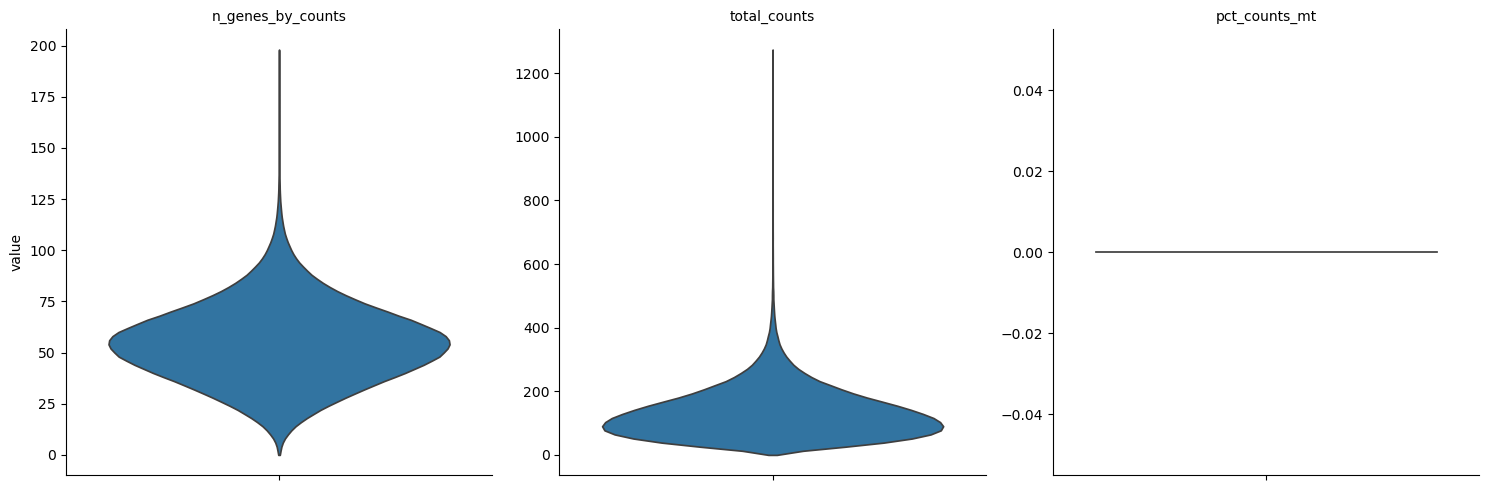

In [6]:
sc.pl.violin(
    adata_gexp_raw,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    jitter=0.2,
    multi_panel=True,
    stripplot=False, # too many points to see anything
)

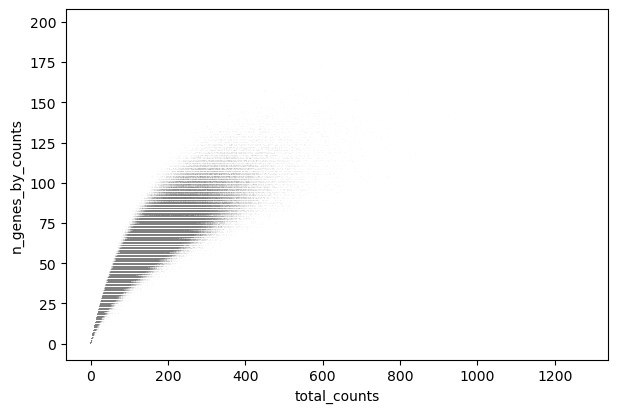

In [7]:
sc.pl.scatter(adata_gexp_raw, "total_counts", "n_genes_by_counts")

In [24]:
print(adata_gexp_raw.shape)

# not doing this step because our resulting data is then out of sync when we merge with morphology
# sc.pp.filter_cells(adata_gexp_raw, min_genes=100) # only cells with at least 100 genes expressed

sc.pp.filter_genes(adata_gexp_raw, min_cells=100) # only genes expressed in at least 100 cells
print(adata_gexp_raw.shape)

(940131, 380)
(940131, 380)


In [8]:
adata_gexp_raw.layers["counts"] = adata_gexp_raw.X.copy()
sc.pp.normalize_total(adata_gexp_raw)
sc.pp.log1p(adata_gexp_raw)

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/scanpy/preprocessing/_normalization.py:234: UserWarning: Some cells have zero counts
  warn(UserWarning("Some cells have zero counts"))


In [9]:
# drops to 100 genes, we don't want that - let's trust the panel

# sc.pp.highly_variable_genes(adata_gexp_raw, flavor="seurat", batch_key="sample")
# adata_gexp_hvg = adata_gexp_raw[:, adata_gexp_raw.var["highly_variable"]].copy()
# adata_gexp_hvg

adata_gexp_hvg = adata_gexp_raw.copy()

In [10]:
adata_gexp_hvg.obs["sample"]

0           sample1
1           sample1
2           sample1
3           sample1
4           sample1
             ...   
365599-1    sample2
365600-1    sample2
365601-1    sample2
365602-1    sample2
365603-1    sample2
Name: sample, Length: 940131, dtype: category
Categories (2, object): ['sample1', 'sample2']

In [11]:
adata_gexp_hvg

AnnData object with n_obs × n_vars = 940131 × 380
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'region', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb'
    var: 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    uns: 'log1p'
    obsm: 'spatial'
    layers: 'counts'

In [12]:
sc.tl.pca(adata_gexp_hvg)
sce.pp.harmony_integrate(adata_gexp_hvg, key="sample", max_iter_harmony=10)

2025-05-18 13:18:21,646 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2025-05-18 13:19:28,527 - harmonypy - INFO - sklearn.KMeans initialization complete.
2025-05-18 13:19:32,511 - harmonypy - INFO - Iteration 1 of 10
2025-05-18 13:27:39,319 - harmonypy - INFO - Iteration 2 of 10
2025-05-18 13:35:39,283 - harmonypy - INFO - Converged after 2 iterations


In [13]:
%%time

sc.pp.neighbors(adata_gexp_hvg, use_rep="X_pca_harmony")

CPU times: user 4min 29s, sys: 5.05 s, total: 4min 34s
Wall time: 4min 39s


In [14]:
%%time

sc.tl.umap(adata_gexp_hvg)

CPU times: user 1h 44min 21s, sys: 4.72 s, total: 1h 44min 26s
Wall time: 22min 29s


In [15]:
%%time

sc.tl.leiden(adata_gexp_hvg)

<timed eval>:1: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.


CPU times: user 34min 52s, sys: 47.9 s, total: 35min 40s
Wall time: 35min 45s


In [17]:
adata_gexp_hvg.write(data_dir / "xenium_gexp_harmony.h5ad")

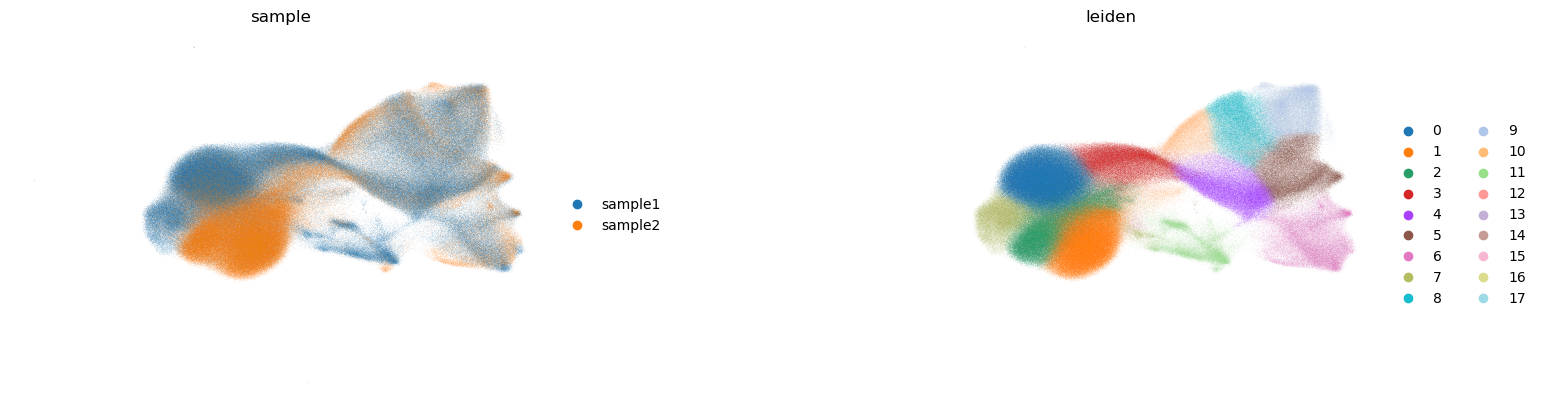

In [18]:
sc.pl.umap(
    adata_gexp_hvg,
    color=["sample", "leiden"],
    wspace=0.4,
    title=["sample", "leiden"],
    frameon=False,
)

In [19]:
markers = dc.get_resource(
    name='PanglaoDB',
    organism='human',
    license='academic'
)
markers

,genesymbol,_entity_type,canonical_marker,cell_type,germ_layer,human,human_sensitivity,human_specificity,mouse,mouse_sensitivity,mouse_specificity,ncbi_tax_id,organ,ubiquitiousness
,,,,,,,,,,,,,,
0,A0A068BD53,protein,True,B cells,Mesoderm,False,0.0,0.0,True,0.391473,0.00274026,10090,Immune system,0.007
1,A0A068BGV1,protein,True,Dendritic cells,Mesoderm,False,0.0,0.0,True,0.142857,0.000193013,10090,Immune system,0.0
2,A0A068BGW6,protein,True,B cells,Mesoderm,False,0.0,0.0,True,0.391473,0.00274026,10090,Immune system,0.007
3,A0A087WRN7,protein,False,Salivary mucous cells,Ectoderm,False,<NA>,<NA>,True,<NA>,<NA>,10090,Oral cavity,0.001
4,A0A0F6QAG2,protein,True,NK cells,Mesoderm,False,0.0,0.0,True,0.37234,0.000129107,10090,Immune system,0.002
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8456,ZNF521,protein,False,Adipocyte progenitor cells,Mesoderm,True,0.0,0.0103383,False,0.0,0.0,9606,Connective tissue,0.002
8457,ZNRF4,protein,False,Germ cells,Mesoderm,True,0.28436,0.0,True,0.0,0.0,9606,Reproductive,0.01
8458,ZPBP2,protein,True,Germ cells,Mesoderm,True,0.436019,0.0,True,0.0,0.0,9606,Reproductive,0.008


In [20]:
markers = markers[markers['human'].astype(bool) & markers['canonical_marker'].astype(bool) & (markers['human_sensitivity'].astype(float) > 0.5)]

# Remove duplicated entries
markers = markers[~markers.duplicated(['cell_type', 'genesymbol'])]
markers

,genesymbol,_entity_type,canonical_marker,cell_type,germ_layer,human,human_sensitivity,human_specificity,mouse,mouse_sensitivity,mouse_specificity,ncbi_tax_id,organ,ubiquitiousness
,,,,,,,,,,,,,,
38,AAK1,protein,False,Neurons,Ectoderm,True,0.555556,0.0320452,True,0.470588,0.0213838,9606,Brain,0.044
50,ABCA3,protein,True,Pulmonary alveolar type II cells,Endoderm,True,0.692308,0.000943693,True,0.00757576,0.000517699,9606,Lungs,0.001
85,ACADVL,protein,False,Basal cells,Mesoderm,True,0.76,0.213018,True,1.0,0.00603183,9606,Epithelium,0.05
122,ACSL5,protein,True,Enterocytes,Endoderm,True,0.666667,0.0153798,True,0.728477,0.0501211,9606,GI tract,0.055
133,ACTA2,protein,True,Smooth muscle cells,Mesoderm,True,0.904762,0.0135604,True,1.0,0.0313632,9606,Smooth muscle,0.035
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8383,WT1,protein,False,Mesothelial cells,Mesoderm,True,1.0,0.0219436,True,0.0,0.0,9606,Epithelium,0.01
8387,XCL1,protein,False,Decidual cells,<NA>,True,1.0,0.00971482,True,0.0,0.0,9606,Reproductive,0.006
8389,XCL2,protein,False,Decidual cells,<NA>,True,1.0,0.0103416,False,0.0,0.0,9606,Reproductive,0.002


In [21]:
adata_gexp_hvg_orad = dc.run_ora(
    mat=adata_gexp_hvg,
    net=markers,
    source='cell_type',
    target='genesymbol',
    min_n=3,
    verbose=True,
    use_raw=False
)

113 samples of mat are empty, they will be removed.
Running ora on mat with 940018 samples and 380 targets for 27 sources.


  0%|          | 0/940018 [00:00<?, ?it/s]

In [22]:
adata_gexp_hvg_orad.obsm["ora_estimate"]

source,Acinar cells,B cells,B cells naive,Basal cells,Dendritic cells,Endothelial cells,Enterocytes,Epithelial cells,Fibroblasts,Gamma delta T cells,...,Myoepithelial cells,NK cells,Neutrophils,Pancreatic stellate cells,Plasma cells,Plasmacytoid dendritic cells,Platelets,Smooth muscle cells,T cells,T memory cells
0,2.420803,-0.0,-0.000000,2.545546,-0.000000,-0.000000,-0.0,-0.000000,2.178351,-0.0,...,-0.0,-0.0,2.420803,-0.0,-0.0,-0.0,-0.000000,2.420803,-0.0,-0.0
1,-0.000000,-0.0,-0.000000,-0.000000,-0.000000,2.069597,-0.0,-0.000000,-0.000000,-0.0,...,-0.0,-0.0,2.420803,-0.0,-0.0,-0.0,-0.000000,-0.000000,-0.0,-0.0
2,-0.000000,-0.0,-0.000000,-0.000000,-0.000000,-0.000000,-0.0,-0.000000,4.747024,-0.0,...,-0.0,-0.0,-0.000000,-0.0,-0.0,-0.0,-0.000000,-0.000000,-0.0,-0.0
3,2.420803,-0.0,-0.000000,2.545546,-0.000000,-0.000000,-0.0,2.545546,2.178351,-0.0,...,-0.0,-0.0,-0.000000,-0.0,-0.0,-0.0,-0.000000,-0.000000,-0.0,-0.0
4,2.420803,-0.0,-0.000000,2.545546,-0.000000,-0.000000,-0.0,-0.000000,2.178351,-0.0,...,-0.0,-0.0,-0.000000,-0.0,-0.0,-0.0,-0.000000,-0.000000,-0.0,-0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
365599-1,2.420803,-0.0,-0.000000,-0.000000,-0.000000,-0.000000,-0.0,2.545546,2.178351,-0.0,...,-0.0,-0.0,-0.000000,-0.0,-0.0,-0.0,-0.000000,-0.000000,-0.0,-0.0
365600-1,2.420803,-0.0,-0.000000,-0.000000,-0.000000,-0.000000,-0.0,-0.000000,-0.000000,-0.0,...,-0.0,-0.0,-0.000000,-0.0,-0.0,-0.0,-0.000000,-0.000000,-0.0,-0.0
365601-1,2.420803,-0.0,-0.000000,-0.000000,2.545546,-0.000000,-0.0,2.545546,-0.000000,-0.0,...,-0.0,-0.0,-0.000000,-0.0,-0.0,-0.0,-0.000000,2.420803,-0.0,-0.0
365602-1,2.420803,-0.0,-0.000000,2.545546,-0.000000,2.069597,-0.0,2.545546,-0.000000,-0.0,...,-0.0,-0.0,2.420803,-0.0,-0.0,-0.0,2.545546,-0.000000,-0.0,-0.0


In [23]:
acts = dc.get_acts(adata_gexp_hvg_orad, obsm_key='ora_estimate')

# We need to remove inf and set them to the maximum value observed for pvals=0
acts_v = acts.X.ravel()
max_e = np.nanmax(acts_v[np.isfinite(acts_v)])
acts.X[~np.isfinite(acts.X)] = max_e

acts

AnnData object with n_obs × n_vars = 940018 × 27
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'region', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'leiden'
    uns: 'log1p', 'pca', 'neighbors', 'umap', 'leiden', 'sample_colors', 'leiden_colors'
    obsm: 'spatial', 'X_pca', 'X_pca_harmony', 'X_umap', 'ora_estimate', 'ora_pvals'

In [24]:
df = dc.rank_sources_groups(acts, groupby='leiden', reference='rest', method='t-test_overestim_var')
df

,group,reference,names,statistic,meanchange,pvals,pvals_adj
0,0,rest,Acinar cells,314.053162,0.984684,0.0,0.0
1,0,rest,Luminal epithelial cells,230.534271,1.550479,0.0,0.0
2,0,rest,Keratinocytes,225.018814,1.012390,0.0,0.0
3,0,rest,Epithelial cells,211.470245,0.830330,0.0,0.0
4,0,rest,Mesangial cells,183.555298,0.554513,0.0,0.0
...,...,...,...,...,...,...,...
400,9,rest,Basal cells,-144.251694,-0.944017,0.0,0.0
401,9,rest,Mammary epithelial cells,-148.014786,-1.266795,0.0,0.0
402,9,rest,Mesangial cells,-184.225494,-1.283179,0.0,0.0
403,9,rest,Luminal epithelial cells,-197.252670,-2.126425,0.0,0.0


In [26]:
n_ctypes = 3
ctypes_dict = df.groupby('group').head(n_ctypes).groupby('group')['names'].apply(lambda x: list(x)).to_dict()
ctypes_dict

{'0': ['Acinar cells', 'Luminal epithelial cells', 'Keratinocytes'],
 '1': ['Mesothelial cells', 'Mammary epithelial cells', 'Acinar cells'],
 '10': ['Macrophages', 'Neutrophils', 'Platelets'],
 '11': ['Smooth muscle cells', 'Myoepithelial cells', 'Keratinocytes'],
 '12': ['Enterocytes', 'Fibroblasts', 'Neutrophils'],
 '13': ['Luminal epithelial cells', 'Epithelial cells', 'Acinar cells'],
 '14': ['Mast cells', 'Dendritic cells', 'Macrophages'],
 '2': ['Acinar cells', 'Mammary epithelial cells', 'Mesothelial cells'],
 '3': ['Mesangial cells', 'Acinar cells', 'Keratinocytes'],
 '4': ['Fibroblasts', 'Smooth muscle cells', 'Pancreatic stellate cells'],
 '5': ['Fibroblasts', 'Pancreatic stellate cells', 'Dendritic cells'],
 '6': ['Endothelial cells',
  'Smooth muscle cells',
  'Pancreatic stellate cells'],
 '7': ['Mesangial cells', 'Epithelial cells', 'Keratinocytes'],
 '8': ['Neutrophils', 'Macrophages', 'Dendritic cells'],
 '9': ['T memory cells', 'T cells', 'NK cells']}

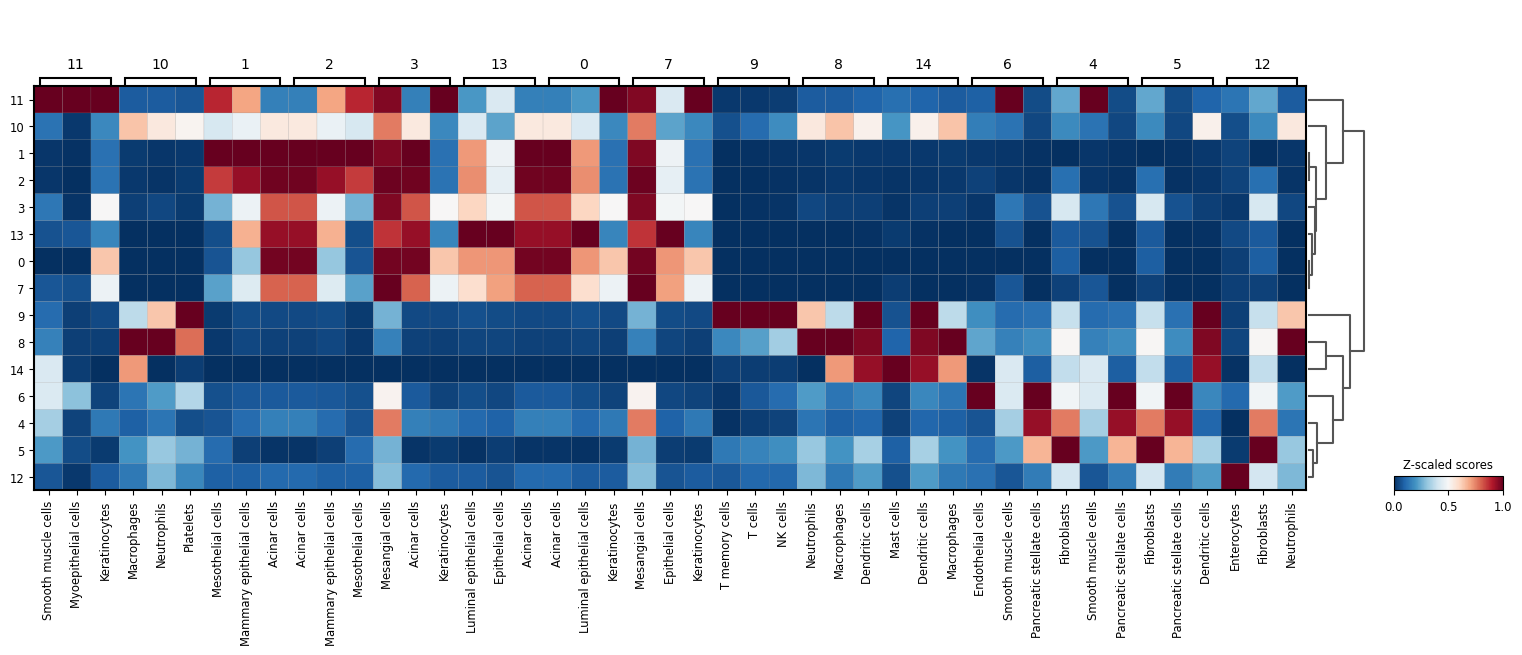

In [27]:
sc.pl.matrixplot(acts, ctypes_dict, 'leiden', dendrogram=True, standard_scale='var',
                 colorbar_title='Z-scaled scores', cmap='RdBu_r')

In [28]:
annotation_dict = df.groupby('group').head(1).set_index('group')['names'].to_dict()
annotation_dict

{'0': 'Acinar cells',
 '1': 'Mesothelial cells',
 '10': 'Macrophages',
 '11': 'Smooth muscle cells',
 '12': 'Enterocytes',
 '13': 'Luminal epithelial cells',
 '14': 'Mast cells',
 '2': 'Acinar cells',
 '3': 'Mesangial cells',
 '4': 'Fibroblasts',
 '5': 'Fibroblasts',
 '6': 'Endothelial cells',
 '7': 'Mesangial cells',
 '8': 'Neutrophils',
 '9': 'T memory cells'}

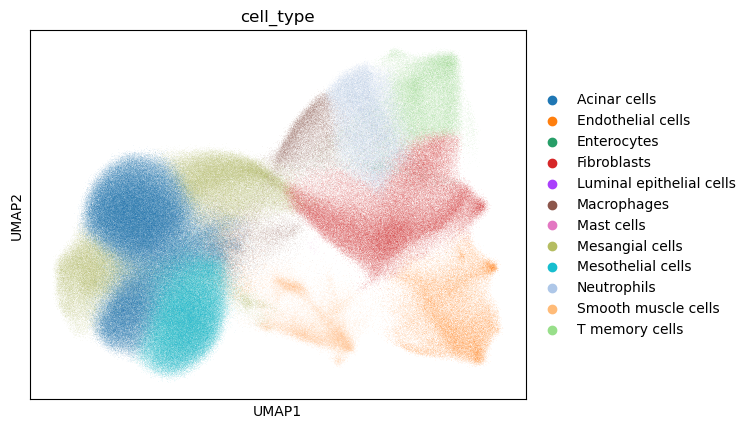

In [29]:
adata_gexp_hvg_orad.obs['cell_type'] = [annotation_dict[clust] for clust in adata_gexp_hvg_orad.obs['leiden']]

# Visualize
sc.pl.umap(adata_gexp_hvg_orad, color='cell_type')

ChatGPT:

```
The reason it screams “pancreas” is that only the exocrine pancreas has:

Huge Acinar cell mass (blue)
– These zymogen-secreting epithelial cells are essentially unique to the pancreas.

Ductal/Luminal epithelial cells (purple)
– Those clusters represent the intralobular and interlobular ducts that carry acinar secretions to the duodenum.

Stellate-like/“mesangial” cells (olive) plus mesothelial cells (teal)
– Pancreatic stellate cells (often mis-annotated as “mesangial”) sit in the periacinar space; true mesothelial cells line the capsule.

Supporting stromal compartments

Fibroblasts (red)

Endothelia (orange) and smooth muscle (light orange) in the vasculature

Resident immune cells
– Macrophages (brown), mast cells (pink), neutrophils (light blue), T-memory cells (pale green)

No other glandular organ combines a dominant acinar epithelium with that precise mix of ductal, stellate, mesothelial, vascular and immune populations. That cellular architecture is classic exocrine pancreas.
```

Okay, it comes from lung. Different strategy